# Scaling Law Analysis - Results Visualization

This notebook loads previously saved results and regenerates all scaling law plots using the functions from plots.py.

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from scipy import stats
from typing import Dict, List, Optional, Tuple
import os
import warnings
warnings.filterwarnings('ignore')

# Set up notebook for inline plotting
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 8)

## Load the Results Data

In [2]:
# Load the results CSV
results_path = '/cis/home/xhan56/code/scaling_law/src/outputs/scaling_laws_full_multi_gpu_20250711_113852/results/scaling_law_results.csv'
df = pd.read_csv(results_path)

print(f"Loaded {len(df)} experiments")
print(f"Columns: {df.columns.tolist()}")
print(f"Experiment types: {df['experiment_type'].unique()}")
print(f"Model parameter counts: {sorted(df['model_params'].unique())}")
print(f"Dataset sizes: {sorted(df['dataset_size'].unique())}")

# Display first few rows
df.head()

Loaded 117 experiments
Columns: ['experiment_type', 'model_name', 'model_params', 'dataset_size', 'final_loss', 'final_perplexity', 'test_loss', 'test_perplexity', 'total_steps', 'total_time', 'total_flops', 'petaflop_days', 'total_time_seconds', 'tflops_per_second', 'steps']
Experiment types: ['standard' 'linear' 'nonlinear' 'clustering']
Model parameter counts: [827088, 1691872, 3582016, 8150400, 21026048]
Dataset sizes: [3000000, 10000000, 30000000, 100000000, 300000000, 1000000000, 3000000000]


,experiment_type,model_name,model_params,dataset_size,final_loss,final_perplexity,test_loss,test_perplexity,total_steps,total_time,total_flops,petaflop_days,total_time_seconds,tflops_per_second,steps
0,standard,model_size_0,827088,3000000,7.636067,2071.581055,7.693499,2194.037354,1000,34.384255,60979544064000,7.057818e-07,33.086804,1.843017,1000
1,standard,model_size_0,827088,10000000,7.605647,2009.510864,7.589692,1977.704468,2441,63.268687,148851067060224,1.722813e-06,61.581585,2.417136,2441
2,standard,model_size_0,827088,30000000,7.337133,1536.301880,7.339592,1540.083618,7324,195.872919,446614180724736,5.169146e-06,192.995054,2.314122,7324
3,standard,model_size_0,827088,100000000,7.171336,1301.581909,7.193291,1330.474243,24414,750.351208,1488754588778496,1.723096e-05,743.322797,2.002837,24414
4,standard,model_size_0,827088,300000000,7.141607,1263.456909,7.161182,1288.432861,73242,2213.420901,4466263766335488,5.169287e-05,2206.401692,2.024230,73242


## Plot Setup Functions

In [38]:
def setup_plot_style():
    """Set up matplotlib style for publication-quality plots with a white background and no grids."""
    plt.style.use('default')
    plt.rcParams['figure.facecolor'] = 'white'
    plt.rcParams['axes.facecolor'] = 'white'
    plt.rcParams['axes.grid'] = False
    plt.rcParams['grid.color'] = 'white'
    plt.rcParams['figure.figsize'] = (10, 10)
    plt.rcParams['font.size'] = 24
    plt.rcParams['axes.labelsize'] = 24
    plt.rcParams['axes.titlesize'] = 28
    plt.rcParams['legend.fontsize'] = 22
    plt.rcParams['xtick.labelsize'] = 22
    plt.rcParams['ytick.labelsize'] = 22
    
    # Set color palette
    colors = sns.color_palette("husl", 8)
    return colors

## Plot Functions

In [39]:
def plot_loss_vs_parameters(
    df: pd.DataFrame,
    save_path: Optional[str] = None,
    title: str = "Test Loss vs Model Parameters",
) -> plt.Figure:
    """
    Plot test loss vs model parameters (similar to Figure 1 in the paper).
    
    Args:
        df: DataFrame with experiment results
        save_path: Path to save the figure
        title: Plot title
    """
    colors = setup_plot_style()
    
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # Check if data is available
    if len(df) == 0:
        ax.text(0.5, 0.5, 'No data available', 
                horizontalalignment='center', verticalalignment='center', 
                transform=ax.transAxes, fontsize=14)
        ax.set_xlabel('Model Parameters')
        ax.set_ylabel('Test Loss')
        ax.set_title(title)
        return fig
    
    # Get unique experiment types
    experiment_types = df['experiment_type'].unique() if 'experiment_type' in df.columns else ['all']
    
    for i, exp_type in enumerate(experiment_types):
        if exp_type == 'all':
            subset = df
            label = 'All experiments'
        else:
            subset = df[df['experiment_type'] == exp_type]
            label = exp_type.capitalize()
        
        if len(subset) == 0:
            continue
            
        # Plot all points
        ax.loglog(
            subset['model_params'],
            subset['final_loss'],
            'o',
            color=colors[i % len(colors)],
            markersize=6,
            alpha=0.6,
            label=f'{label} (individual)',
        )
        
        # Calculate average loss for each model size
        avg_loss = subset.groupby('model_params')['final_loss'].mean()
        
        if len(avg_loss) > 1:
            # Plot average trend
            ax.loglog(
                avg_loss.index,
                avg_loss.values,
                'o-',
                color=colors[i % len(colors)],
                markersize=10,
                linewidth=2,
                label=f'{label} (average)',
            )
            
            # Fit power law to averages
            if len(avg_loss) > 2:
                log_params = np.log10(avg_loss.index.values)
                log_loss = np.log10(avg_loss.values)
                slope, intercept, r_value, _, _ = stats.linregress(log_params, log_loss)
                
                # Plot fit
                fit_params = np.logspace(
                    np.log10(avg_loss.index.min()),
                    np.log10(avg_loss.index.max()),
                    100
                )
                fit_loss = 10**(slope * np.log10(fit_params) + intercept)
                ax.loglog(
                    fit_params,
                    fit_loss,
                    '--',
                    color=colors[i % len(colors)],
                    linewidth=2,
                    alpha=0.8,
                    label=f'{label} fit (α={-slope:.3f})',
                )
    
    ax.set_xlabel('Model Parameters')
    ax.set_ylabel('Test Loss')
    ax.set_title(title)
    ax.legend(loc='lower left')
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    
    return fig

In [40]:
def plot_loss_vs_dataset_size(
    df: pd.DataFrame,
    save_path: Optional[str] = None,
    title: str = "Test Loss vs Dataset Size",
) -> plt.Figure:
    """
    Plot test loss vs dataset size (similar to Figure 2 in the paper).
    
    Args:
        df: DataFrame with experiment results
        save_path: Path to save the figure
        title: Plot title
    """
    colors = setup_plot_style()
    
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # Check if data is available
    if len(df) == 0:
        ax.text(0.5, 0.5, 'No data available', 
                horizontalalignment='center', verticalalignment='center', 
                transform=ax.transAxes, fontsize=14)
        ax.set_xlabel('Dataset Size (tokens)')
        ax.set_ylabel('Test Loss')
        ax.set_title(title)
        return fig
    
    # Get unique model sizes (parameters)
    model_sizes = sorted(df['model_params'].unique()) if 'model_params' in df.columns else []
    
    # Plot dashed lines for each model size
    for i, model_size in enumerate(model_sizes):
        subset = df[df['model_params'] == model_size]
        
        if len(subset) == 0:
            continue
            
        # Sort by dataset size for proper line plotting
        subset = subset.sort_values('dataset_size')
        
        # Plot dashed line for this model size
        ax.loglog(
            subset['dataset_size'],
            subset['final_loss'],
            '--',
            color=colors[i % len(colors)],
            linewidth=2,
            alpha=0.8,
            label=f'{model_size:,} params',
        )
        
        # Plot individual points
        ax.loglog(
            subset['dataset_size'],
            subset['final_loss'],
            'o',
            color=colors[i % len(colors)],
            markersize=6,
            alpha=0.6,
        )
    
    # Fit power law to all data and plot as solid line
    if len(df) > 2:
        log_data = np.log10(df['dataset_size'].values)
        log_loss = np.log10(df['final_loss'].values)
        slope, intercept, r_value, _, _ = stats.linregress(log_data, log_loss)
        
        # Plot overall fit as solid line
        fit_data = np.logspace(
            np.log10(df['dataset_size'].min()),
            np.log10(df['dataset_size'].max()),
            100
        )
        fit_loss = 10**(slope * np.log10(fit_data) + intercept)
        ax.loglog(
            fit_data,
            fit_loss,
            '-',
            color='black',
            linewidth=3,
            alpha=0.8,
            label=f'Overall fit (β={-slope:.3f})',
        )
    
    ax.set_xlabel('Dataset Size (tokens)')
    ax.set_ylabel('Test Loss')
    ax.set_title(title)
    ax.legend(loc='lower left')
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    
    return fig

In [41]:
def plot_loss_vs_compute(
    df: pd.DataFrame,
    save_path: Optional[str] = None,
    title: str = "Test Loss vs Compute",
) -> plt.Figure:
    """
    Plot test loss vs compute (similar to Figure 1 in the paper).
    
    Args:
        df: DataFrame with experiment results
        save_path: Path to save the figure
        title: Plot title
    """
    colors = setup_plot_style()
    
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # Filter for rows with compute data
    df_compute = df[df['petaflop_days'].notna()].copy()
    
    if len(df_compute) == 0:
        print("Warning: No compute data available")
        # Create an empty plot with a message
        ax.text(0.5, 0.5, 'No compute data available\nEnable compute tracking in config', 
                horizontalalignment='center', verticalalignment='center', 
                transform=ax.transAxes, fontsize=14)
        ax.set_xlabel('Compute (PetaFLOP-days)')
        ax.set_ylabel('Test Loss')
        ax.set_title(title)
        return fig
    
    # Plot all points
    ax.loglog(
        df_compute['petaflop_days'],
        df_compute['final_loss'],
        'o',
        color=colors[0],
        markersize=8,
        alpha=0.6,
        label='All experiments',
    )
    
    # Fit power law to all data
    log_compute = np.log10(df_compute['petaflop_days'].values)
    log_loss = np.log10(df_compute['final_loss'].values)
    slope, intercept, r_value, _, _ = stats.linregress(log_compute, log_loss)
    
    # Plot fit
    fit_compute = np.logspace(
        np.log10(df_compute['petaflop_days'].min()),
        np.log10(df_compute['petaflop_days'].max()),
        100
    )
    fit_loss = 10**(slope * np.log10(fit_compute) + intercept)
    ax.loglog(
        fit_compute,
        fit_loss,
        '--',
        color='red',
        linewidth=2,
        label=f'Power law fit (γ={-slope:.2f})',
    )
    
    # Highlight efficient frontier (Pareto optimal points)
    # Find points that are not dominated by any other point
    pareto_indices = []
    for i in range(len(df_compute)):
        is_pareto = True
        for j in range(len(df_compute)):
            if i != j:
                # Check if point j dominates point i
                if (df_compute.iloc[j]['petaflop_days'] <= df_compute.iloc[i]['petaflop_days'] and
                    df_compute.iloc[j]['final_loss'] < df_compute.iloc[i]['final_loss']):
                    is_pareto = False
                    break
        if is_pareto:
            pareto_indices.append(i)
    
    if pareto_indices:
        pareto_df = df_compute.iloc[pareto_indices].sort_values('petaflop_days')
        ax.loglog(
            pareto_df['petaflop_days'],
            pareto_df['final_loss'],
            'o-',
            color='green',
            markersize=10,
            linewidth=2,
            label='Efficient frontier',
        )
    
    ax.set_xlabel('Compute (PetaFLOP-days)')
    ax.set_ylabel('Test Loss')
    ax.set_title(title)
    ax.legend(loc='lower left')
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    
    return fig

In [42]:
def plot_optimal_model_size(
    df: pd.DataFrame,
    save_path: Optional[str] = None,
    title: str = "Optimal Model Size vs Compute Budget",
) -> plt.Figure:
    """
    Plot optimal model size vs compute budget (similar to Figure 6 in the paper).
    
    Args:
        df: DataFrame with experiment results
        save_path: Path to save the figure
        title: Plot title
    """
    colors = setup_plot_style()
    
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # Group by compute budget bins
    df_compute = df[df['petaflop_days'].notna()].copy()
    
    if len(df_compute) == 0:
        print("Warning: No compute data available")
        # Create an empty plot with a message
        ax.text(0.5, 0.5, 'No compute data available\nEnable compute tracking in config', 
                horizontalalignment='center', verticalalignment='center', 
                transform=ax.transAxes, fontsize=14)
        ax.set_xlabel('Compute Budget (PetaFLOP-days)')
        ax.set_ylabel('Optimal Model Size (parameters)')
        ax.set_title(title)
        return fig
    
    # Create compute bins
    compute_bins = np.logspace(
        np.log10(df_compute['petaflop_days'].min()),
        np.log10(df_compute['petaflop_days'].max()),
        10
    )
    
    optimal_sizes = []
    compute_centers = []
    
    for i in range(len(compute_bins) - 1):
        # Find experiments in this compute bin
        mask = (df_compute['petaflop_days'] >= compute_bins[i]) & \
               (df_compute['petaflop_days'] < compute_bins[i+1])
        bin_df = df_compute[mask]
        
        if len(bin_df) > 0:
            # Find model with lowest loss in this bin
            best_idx = bin_df['final_loss'].idxmin()
            optimal_sizes.append(bin_df.loc[best_idx, 'model_params'])
            compute_centers.append(np.sqrt(compute_bins[i] * compute_bins[i+1]))
    
    if optimal_sizes:
        # Plot optimal model sizes
        ax.loglog(
            compute_centers,
            optimal_sizes,
            'o-',
            color=colors[0],
            markersize=10,
            linewidth=2,
            label='Optimal model size',
        )
        
        # Fit power law
        if len(optimal_sizes) > 2:
            log_compute = np.log10(compute_centers)
            log_size = np.log10(optimal_sizes)
            slope, intercept, r_value, _, _ = stats.linregress(log_compute, log_size)
            
            # Plot fit
            fit_compute = np.logspace(
                np.log10(min(compute_centers)),
                np.log10(max(compute_centers)),
                100
            )
            fit_size = 10**(slope * np.log10(fit_compute) + intercept)
            ax.loglog(
                fit_compute,
                fit_size,
                '--',
                color='red',
                linewidth=2,
                label=f'N_opt ∝ C^{slope:.2f}',
            )
    
    ax.set_xlabel('Compute Budget (PetaFLOP-days)')
    ax.set_ylabel('Optimal Model Size (parameters)')
    ax.set_title(title)
    ax.legend(loc='lower left')
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    
    return fig

In [58]:
def compare_experiment_types(
    df: pd.DataFrame,
    type1: str,
    type2: str,
    save_path: Optional[str] = None,
) -> plt.Figure:
    """Compare two experiment types."""
    colors = setup_plot_style()
    
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    axes = axes.flatten()
    
    experiment_types = [type1, type2]
    type_colors = colors[:2]
    
    # 1. Loss comparison by model size
    ax = axes[0]
    for exp_type, color in zip(experiment_types, type_colors):
        subset = df[df['experiment_type'] == exp_type]
        if len(subset) > 0:
            model_loss = subset.groupby('model_params')['final_loss'].mean()
            ax.loglog(
                model_loss.index,
                model_loss.values,
                'o-',
                color=color,
                label=exp_type.capitalize(),
                markersize=8,
                linewidth=2,
            )
    ax.set_xlabel('Model Parameters')
    ax.set_ylabel('Average Test Loss')
    ax.set_title('Loss by Model Size')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # 2. Loss comparison by dataset size
    ax = axes[1]
    for exp_type, color in zip(experiment_types, type_colors):
        subset = df[df['experiment_type'] == exp_type]
        if len(subset) > 0:
            data_loss = subset.groupby('dataset_size')['final_loss'].mean()
            ax.loglog(
                data_loss.index,
                data_loss.values,
                'o-',
                color=color,
                label=exp_type.capitalize(),
                markersize=8,
                linewidth=2,
            )
    ax.set_xlabel('Dataset Size (tokens)')
    ax.set_ylabel('Average Test Loss')
    ax.set_title('Loss by Dataset Size')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # 3. Perplexity comparison
    ax = axes[2]
    for exp_type, color in zip(experiment_types, type_colors):
        subset = df[df['experiment_type'] == exp_type]
        if len(subset) > 0 and 'final_perplexity' in subset.columns:
            perplexities = subset['final_perplexity'].dropna().values
            if len(perplexities) > 0:
                ax.hist(
                    perplexities,
                    bins=20,
                    alpha=0.6,
                    color=color,
                    label=exp_type.capitalize(),
                    density=True,
                )
    ax.set_xlabel('Final Perplexity')
    ax.set_ylabel('Density')
    ax.set_title('Perplexity Distribution')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # 4. Relative performance
    ax = axes[3]
    # Match experiments by model and dataset size
    df1 = df[df['experiment_type'] == type1].set_index(['model_name', 'dataset_size'])
    df2 = df[df['experiment_type'] == type2].set_index(['model_name', 'dataset_size'])
    
    common_indices = df1.index.intersection(df2.index)
    if len(common_indices) > 0:
        relative_loss = []
        model_params = []
        
        for idx in common_indices:
            loss1 = df1.loc[idx, 'final_loss']
            loss2 = df2.loc[idx, 'final_loss']
            relative = (loss2 - loss1) / loss1 * 100
            relative_loss.append(relative)
            model_params.append(df1.loc[idx, 'model_params'])
        
        ax.semilogx(model_params, relative_loss, 'o', color=colors[2], markersize=8)
        ax.axhline(y=0, color='black', linestyle='--', alpha=0.5)
        ax.set_xlabel('Model Parameters')
        ax.set_ylabel(f'Relative Loss Increase (%)\n({type2} vs {type1})')
        ax.set_title('Performance Impact')
        ax.grid(True, alpha=0.3)
    else:
        ax.text(0.5, 0.5, 'No common experiments to compare', 
                horizontalalignment='center', verticalalignment='center', 
                transform=ax.transAxes, fontsize=14)
    
    # plt.suptitle(f'Comparison: {type1.capitalize()} vs {type2.capitalize()}', fontsize=16)
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    
    return fig

## Generate All Plots

### 1. Loss vs Model Parameters

Available experiment types: ['standard' 'linear' 'nonlinear' 'clustering']


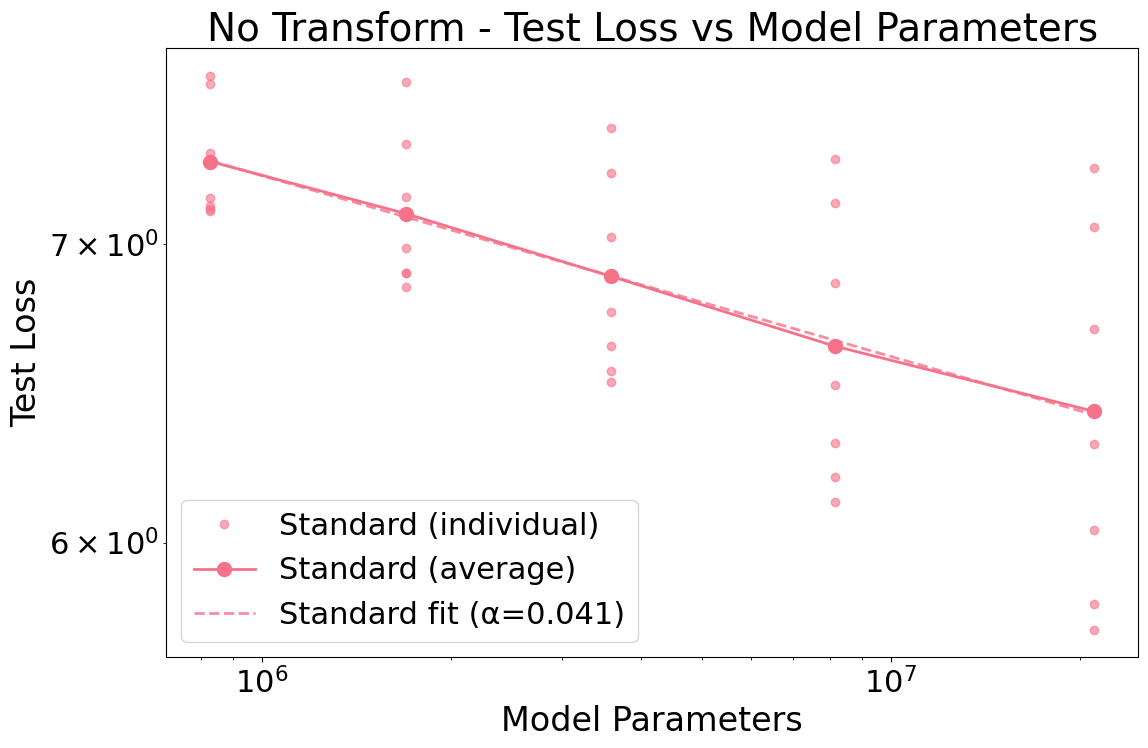

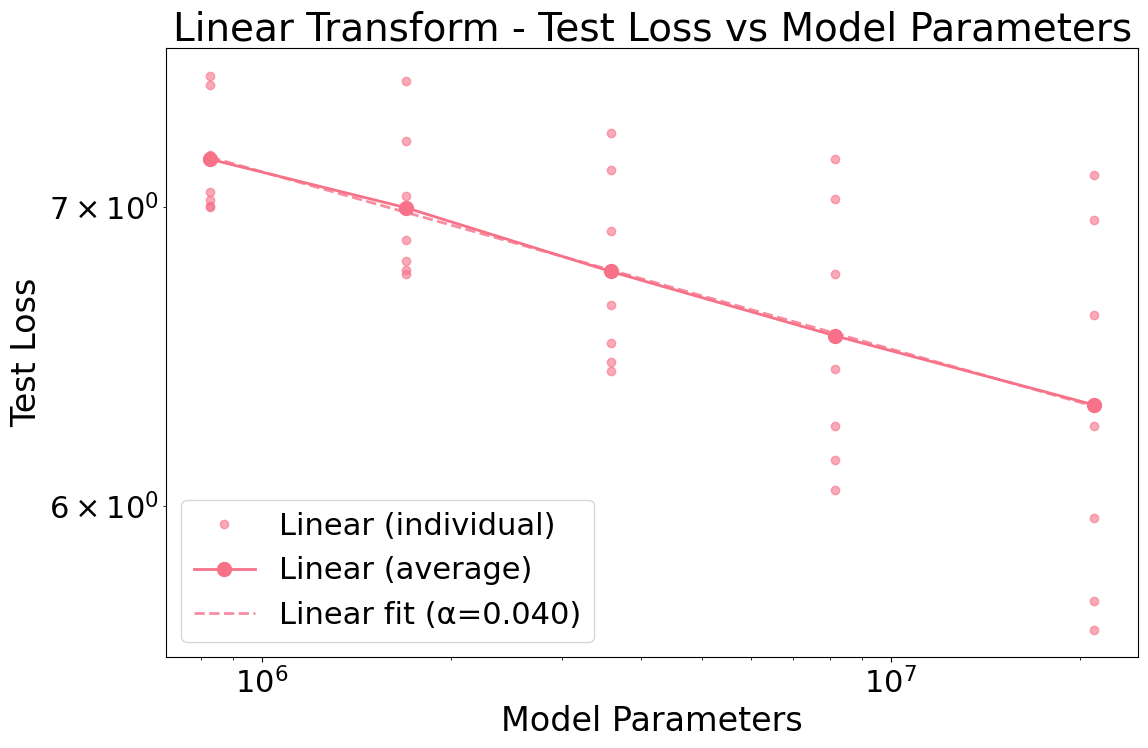

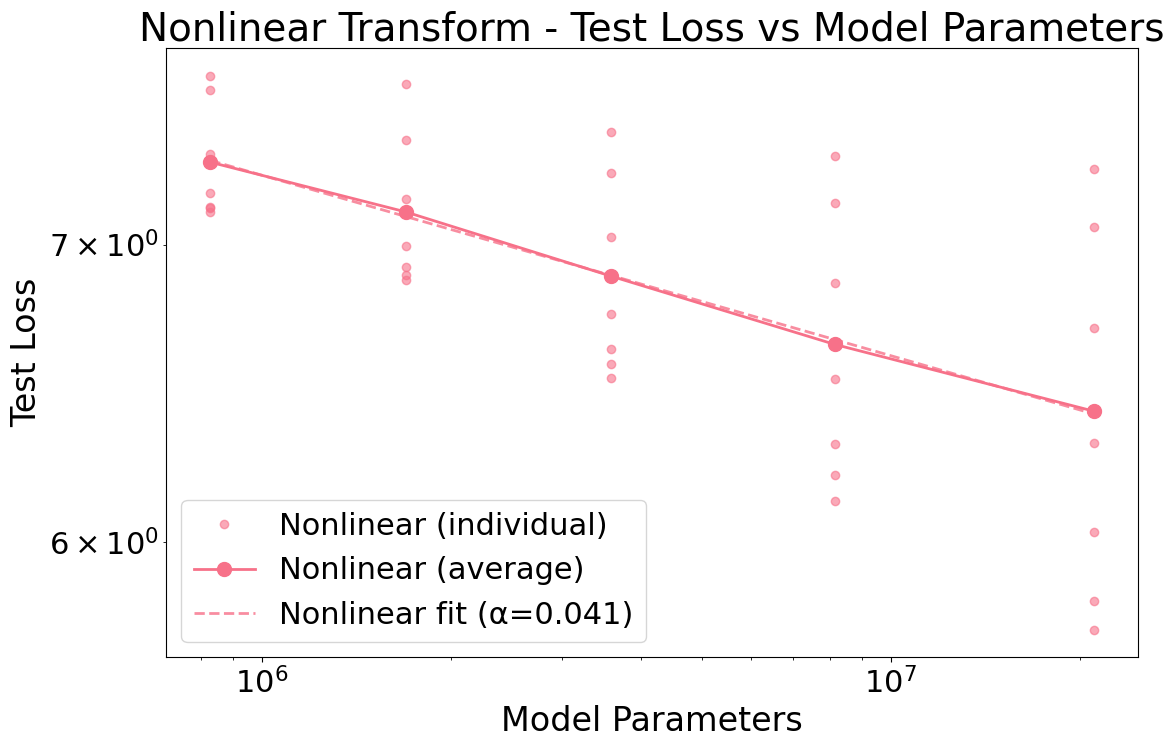

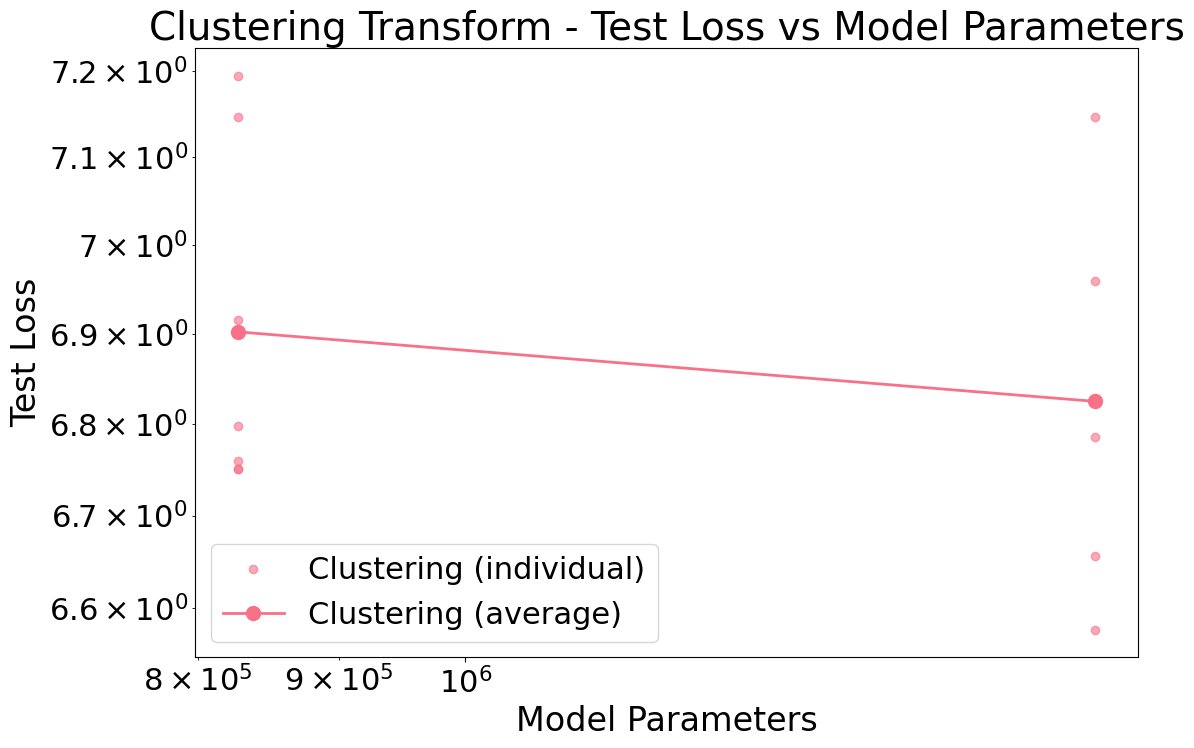

In [51]:
# Plot for each experiment type
experiment_types = df['experiment_type'].unique()
print(f"Available experiment types: {experiment_types}")

for exp_type in experiment_types:
    df_filtered = df[df['experiment_type'] == exp_type]
    if exp_type == 'standard':
        title_name = "No Transform - Test Loss vs Model Parameters"
    else:
        title_name = f"{exp_type.capitalize()} Transform - Test Loss vs Model Parameters"
    fig = plot_loss_vs_parameters(
        df_filtered, 
        title=title_name
    )
    plt.show()

### 2. Loss vs Dataset Size

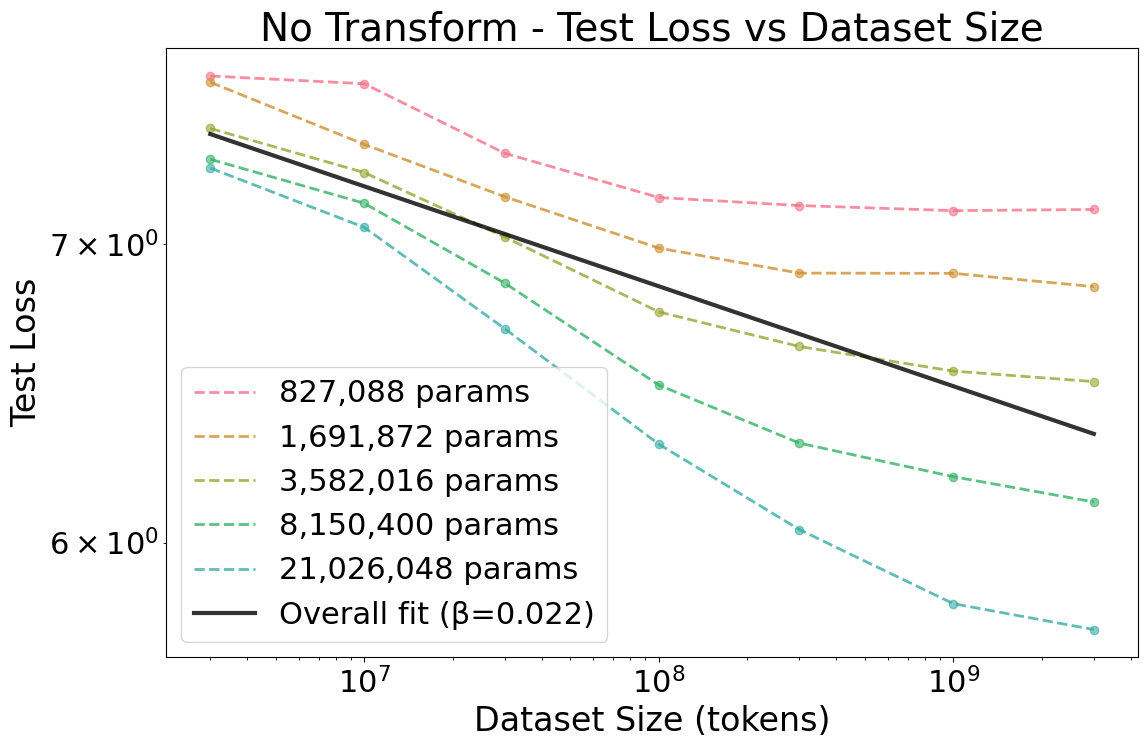

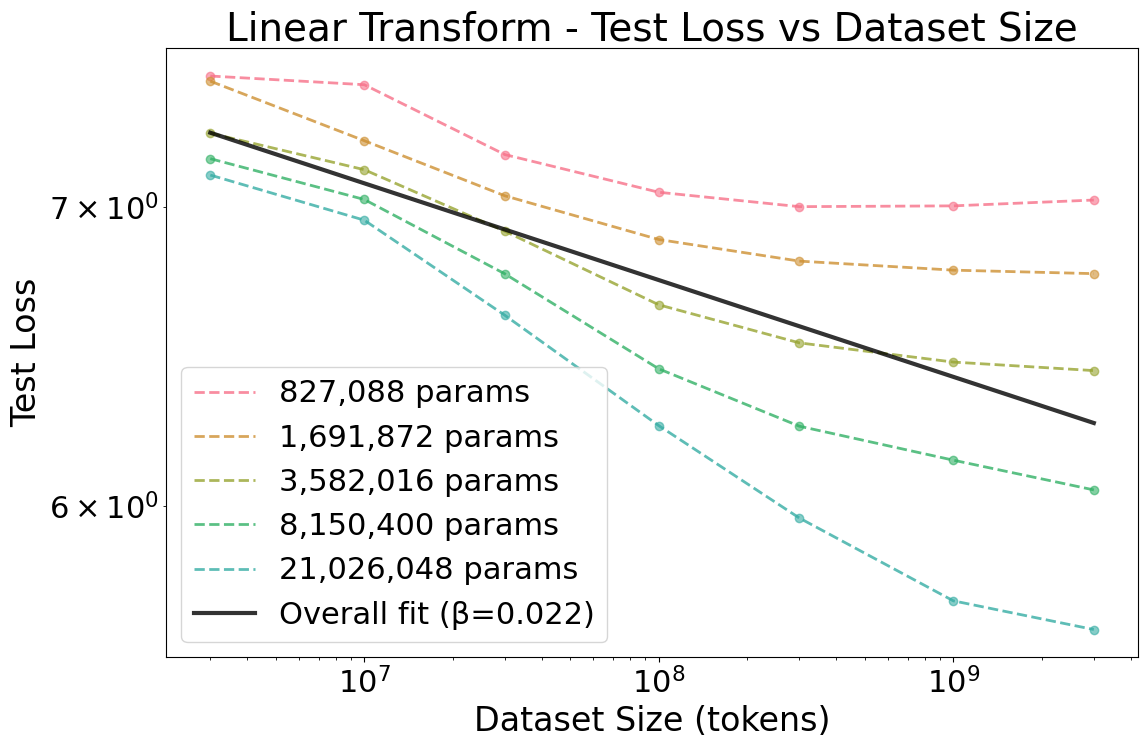

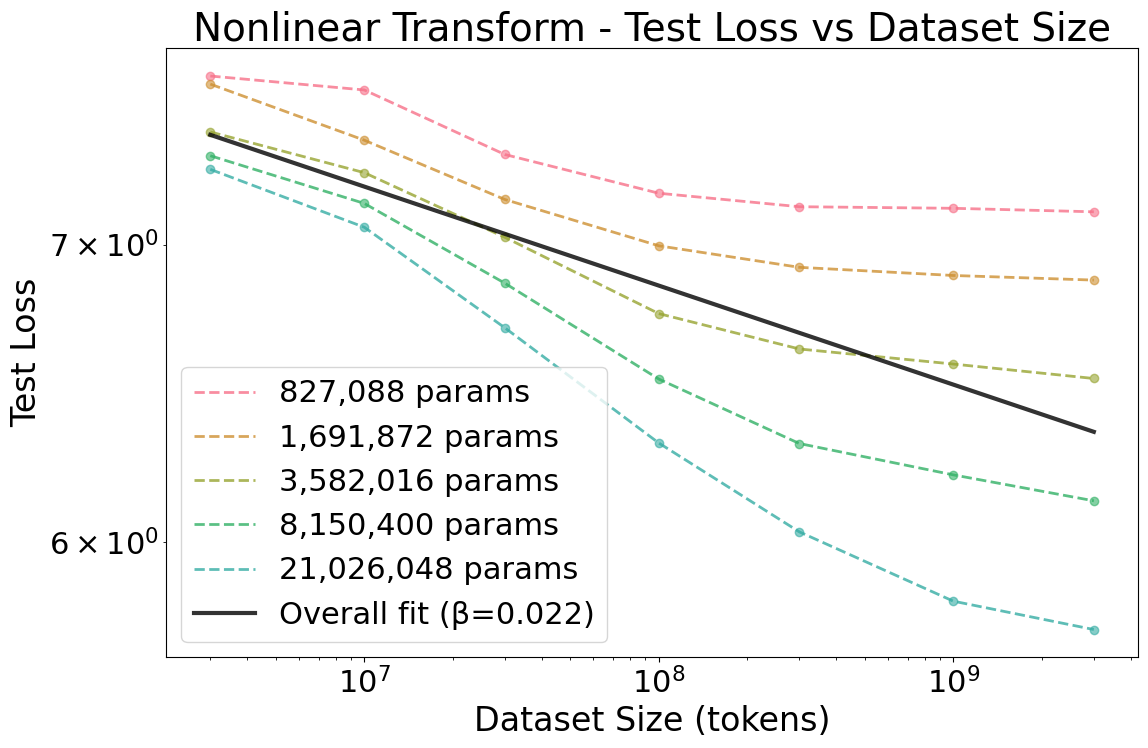

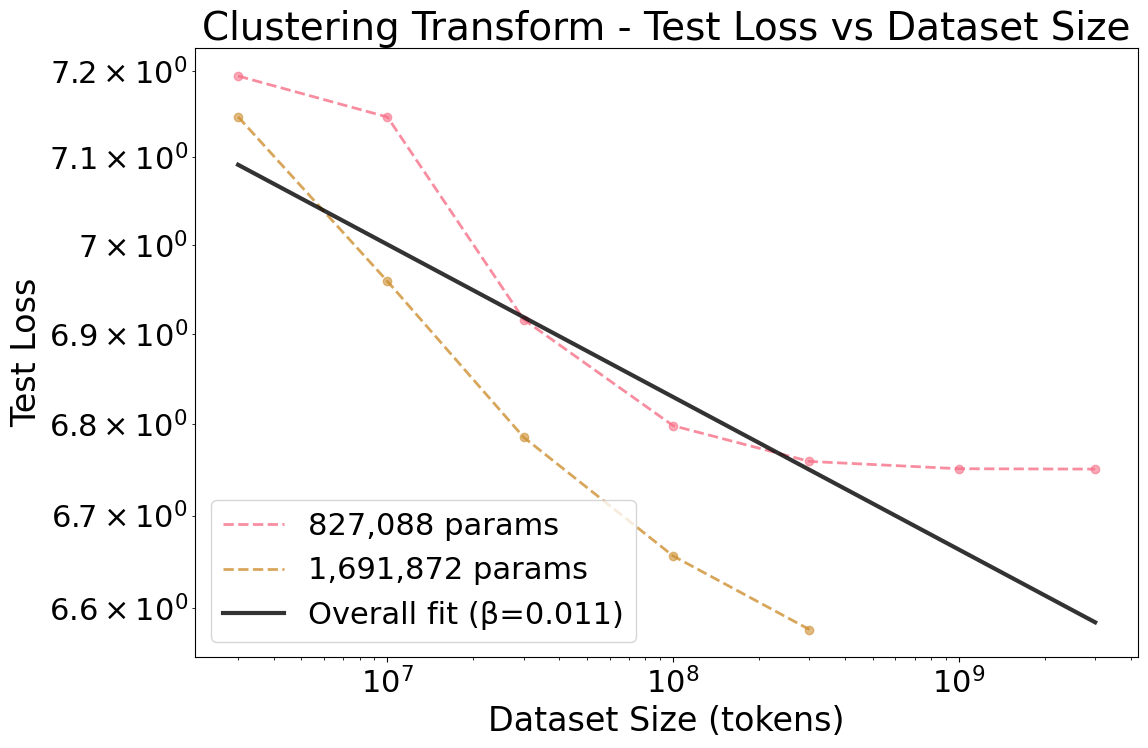

In [53]:
# Plot for each experiment type
for exp_type in experiment_types:
    df_filtered = df[df['experiment_type'] == exp_type]
    if exp_type == 'standard':
        title_name = "No Transform - Test Loss vs Dataset Size"
    else:
        title_name = f"{exp_type.capitalize()} Transform - Test Loss vs Dataset Size"
    fig = plot_loss_vs_dataset_size(
        df_filtered, 
        title=title_name
    )
    plt.show()

### 3. Loss vs Compute

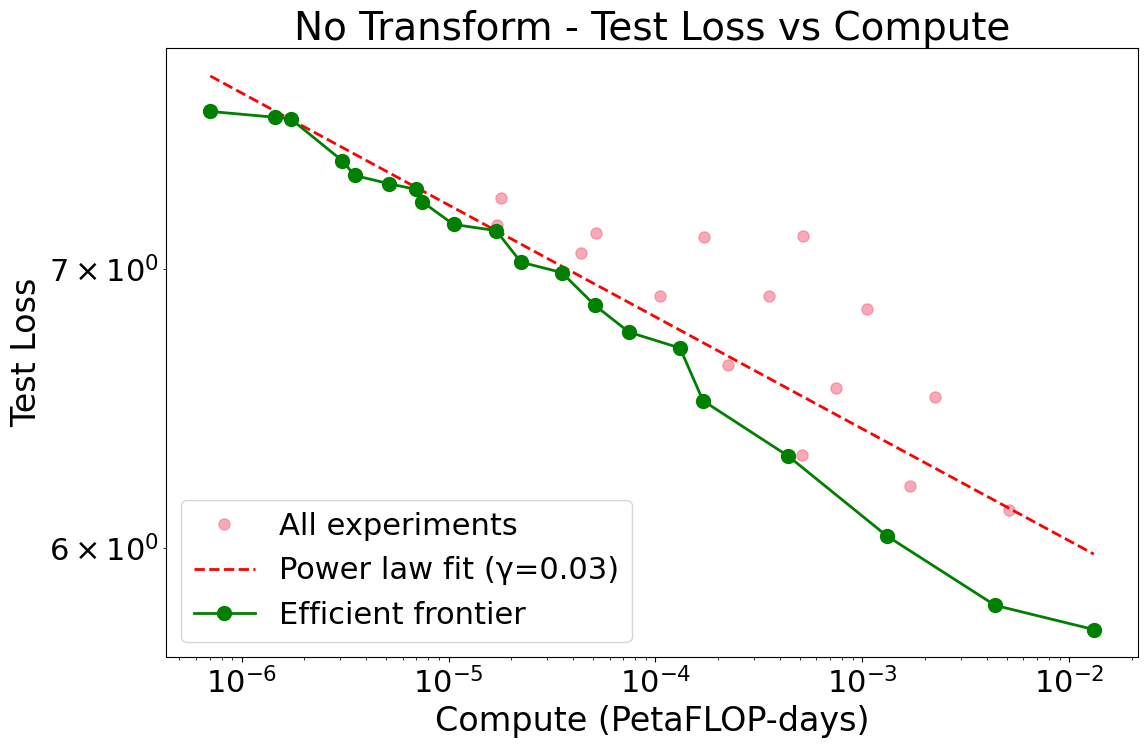

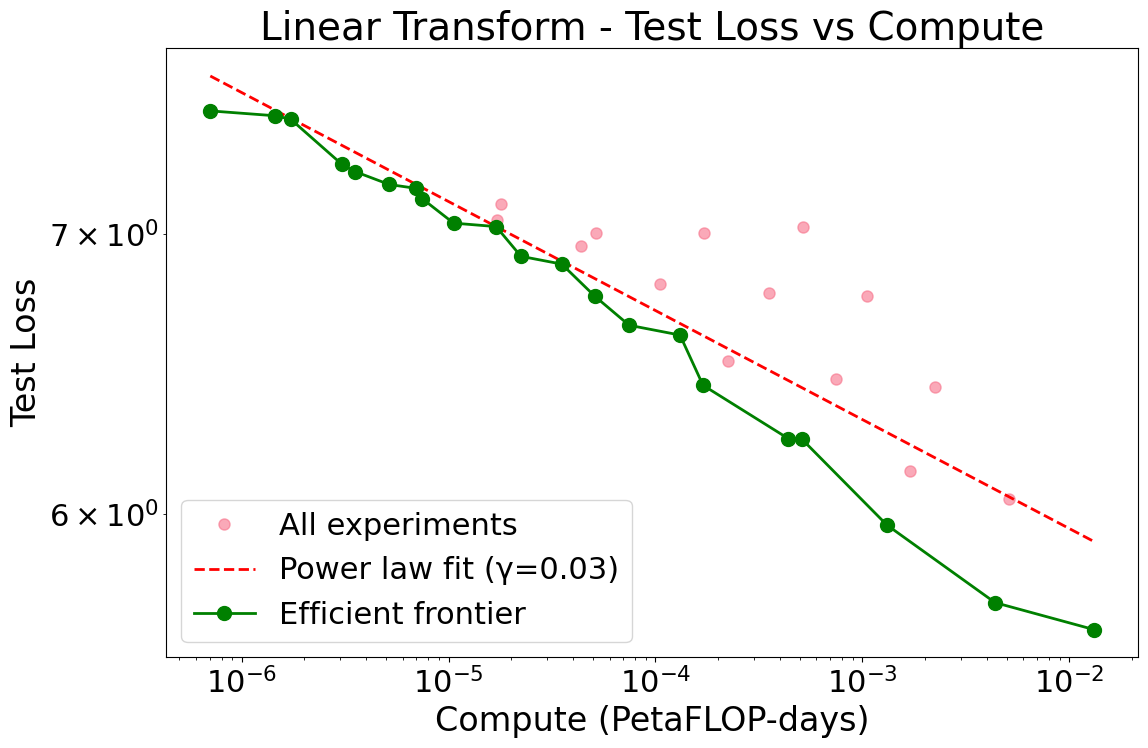

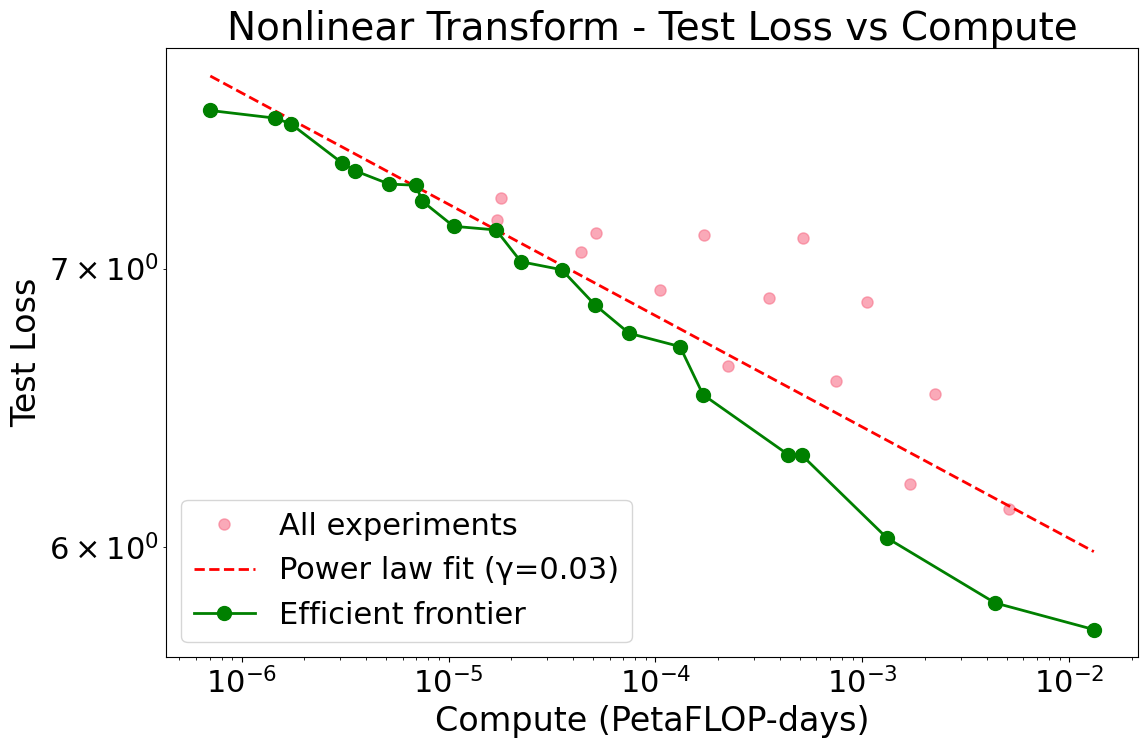

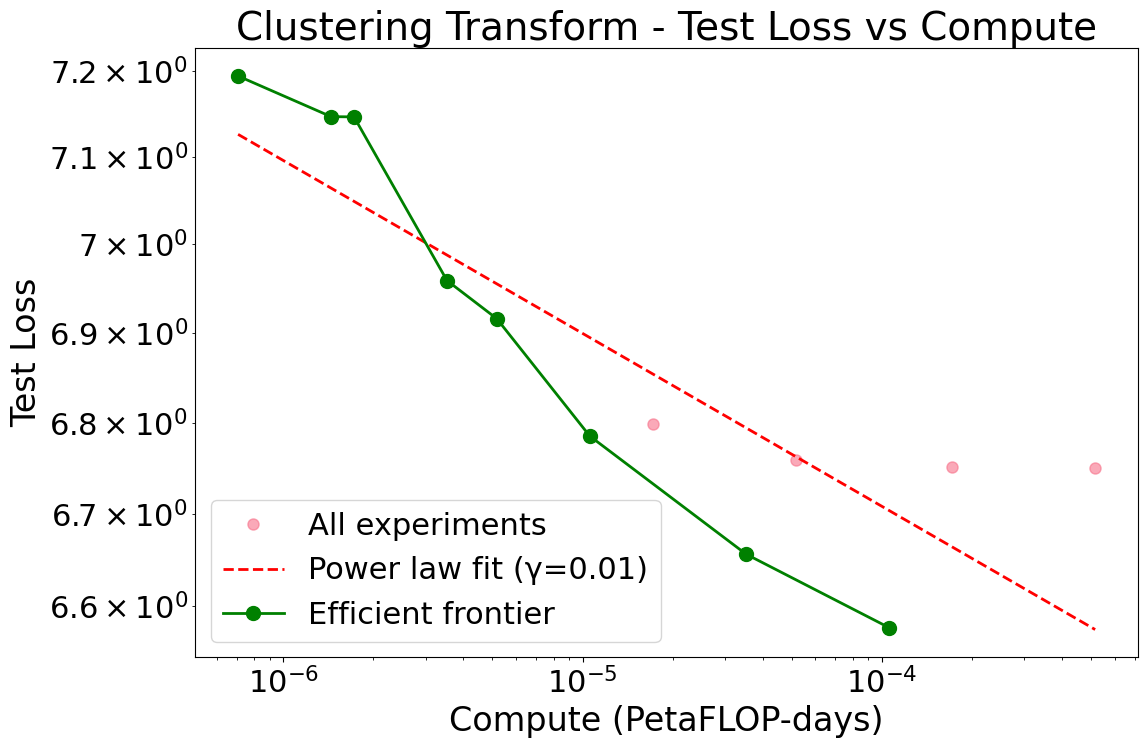

In [54]:
# Plot for each experiment type
for exp_type in experiment_types:
    df_filtered = df[df['experiment_type'] == exp_type]
    if exp_type == 'standard':
        title_name = "No Transform - Test Loss vs Compute"
    else:
        title_name = f"{exp_type.capitalize()} Transform - Test Loss vs Compute"
    fig = plot_loss_vs_compute(
        df_filtered, 
        title=title_name
    )
    plt.show()

### 4. Optimal Model Size vs Compute Budget

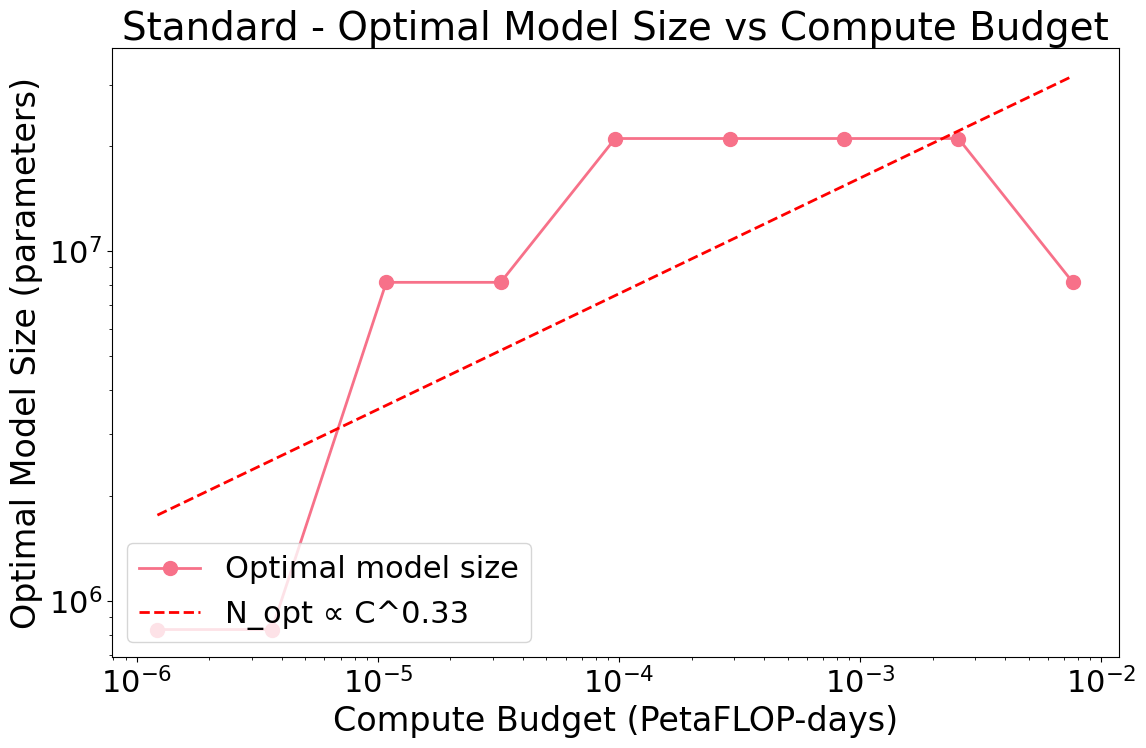

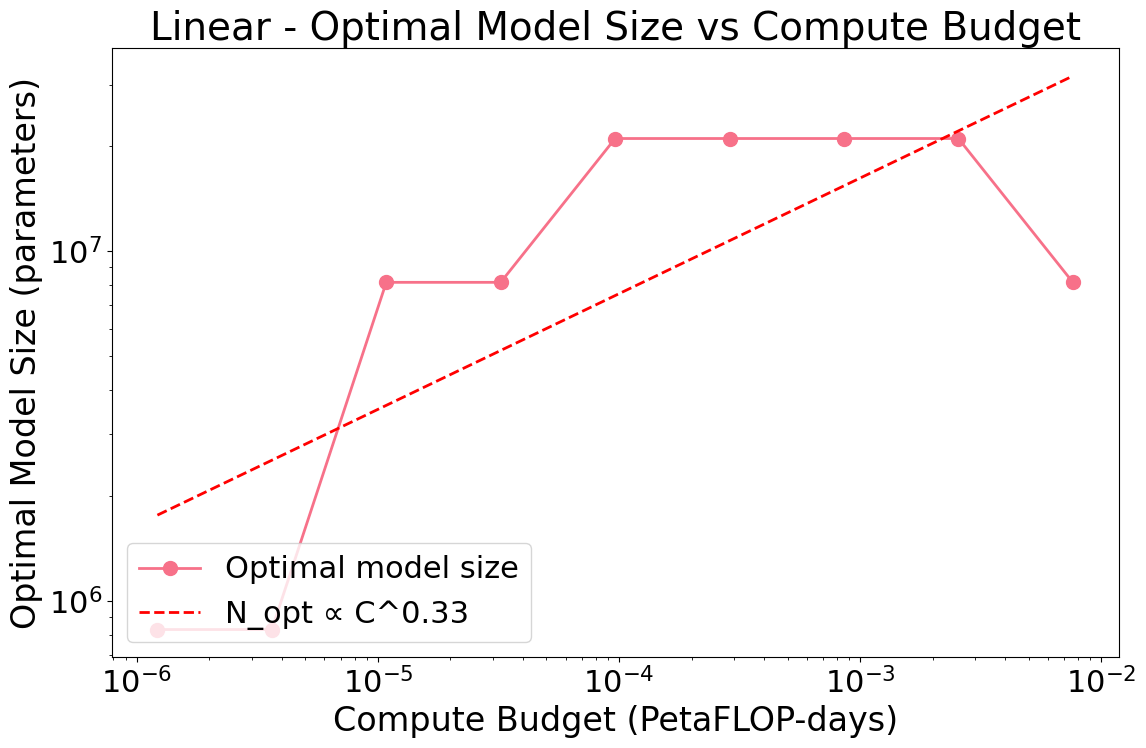

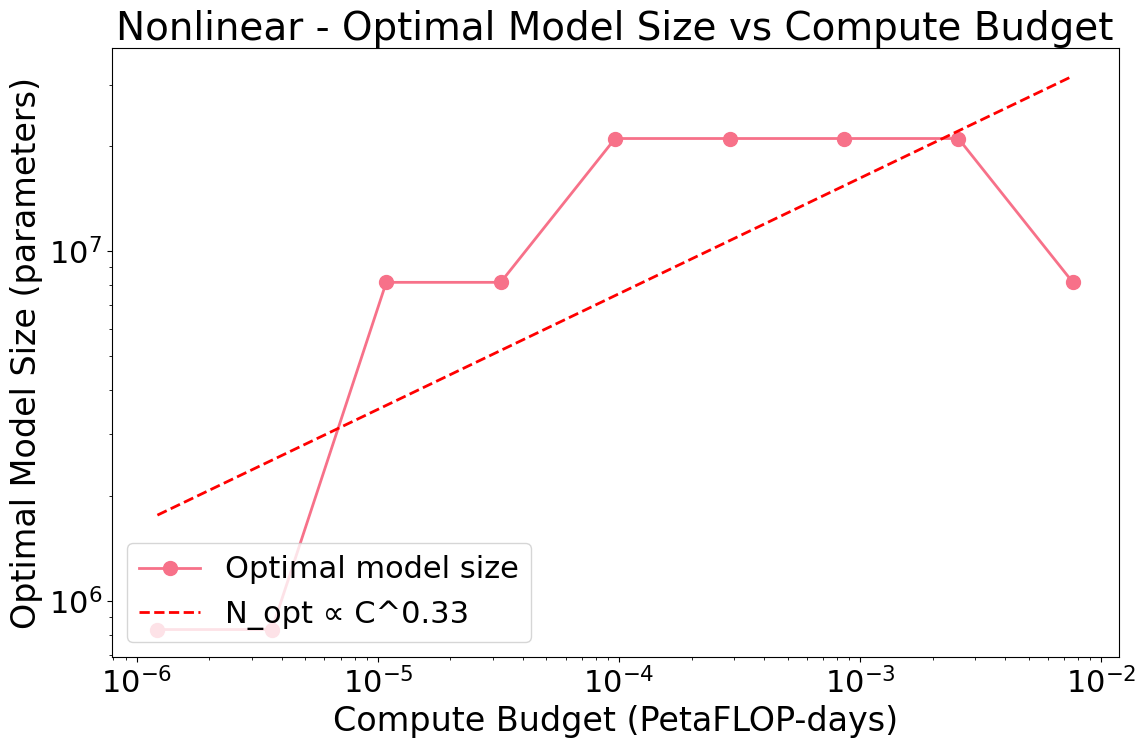

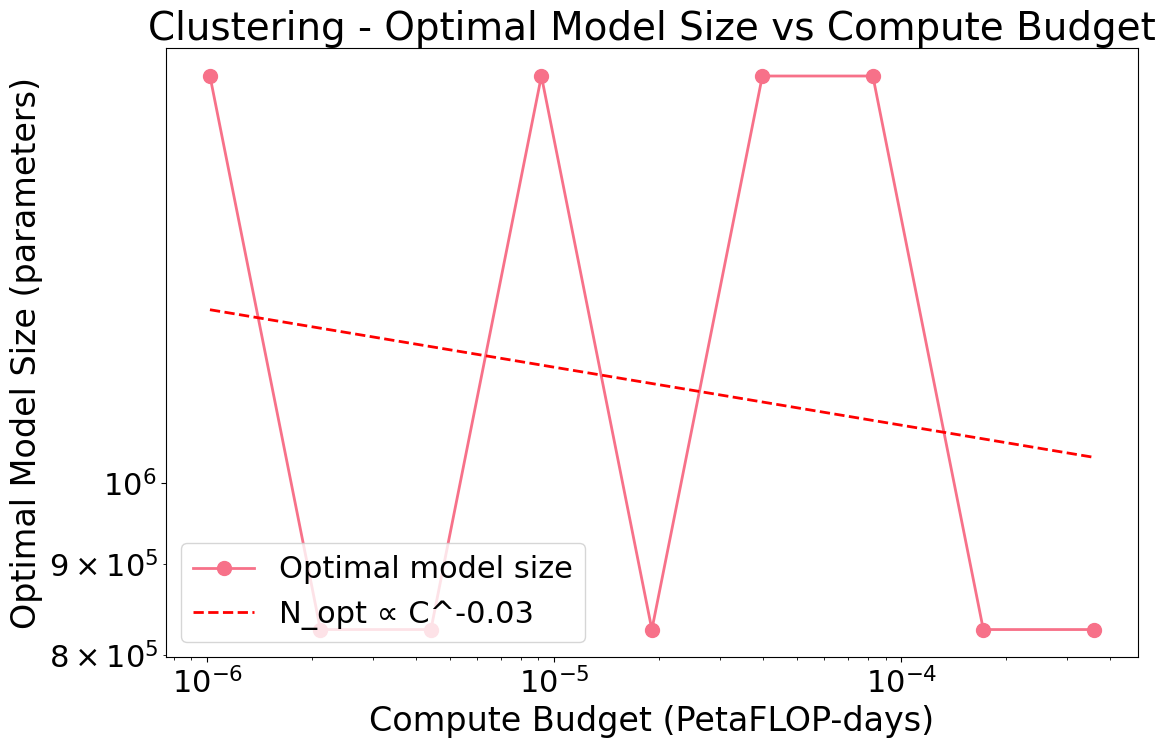

In [55]:
# Plot for each experiment type
for exp_type in experiment_types:
    df_filtered = df[df['experiment_type'] == exp_type]

    fig = plot_optimal_model_size(
        df_filtered, 
        title=f"{exp_type.capitalize()} - Optimal Model Size vs Compute Budget"
    )
    plt.show()

### 5. Comparison Plots


=== Comparing standard vs linear ===


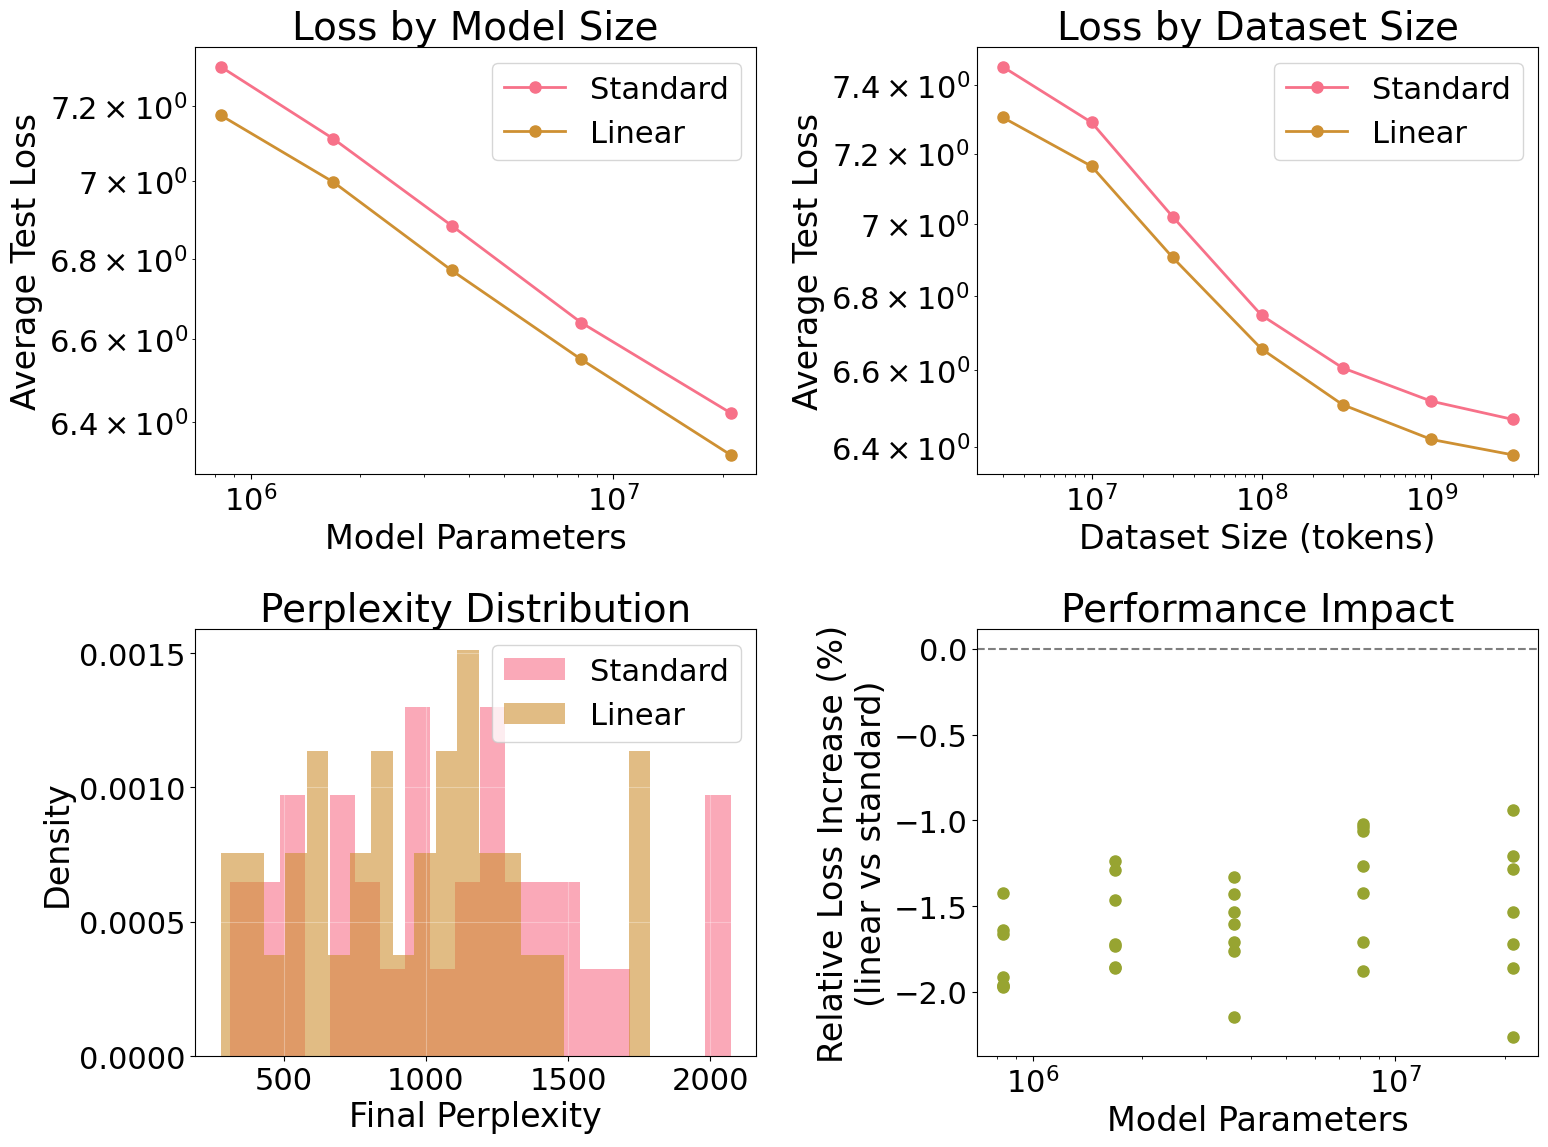


=== Comparing standard vs nonlinear ===


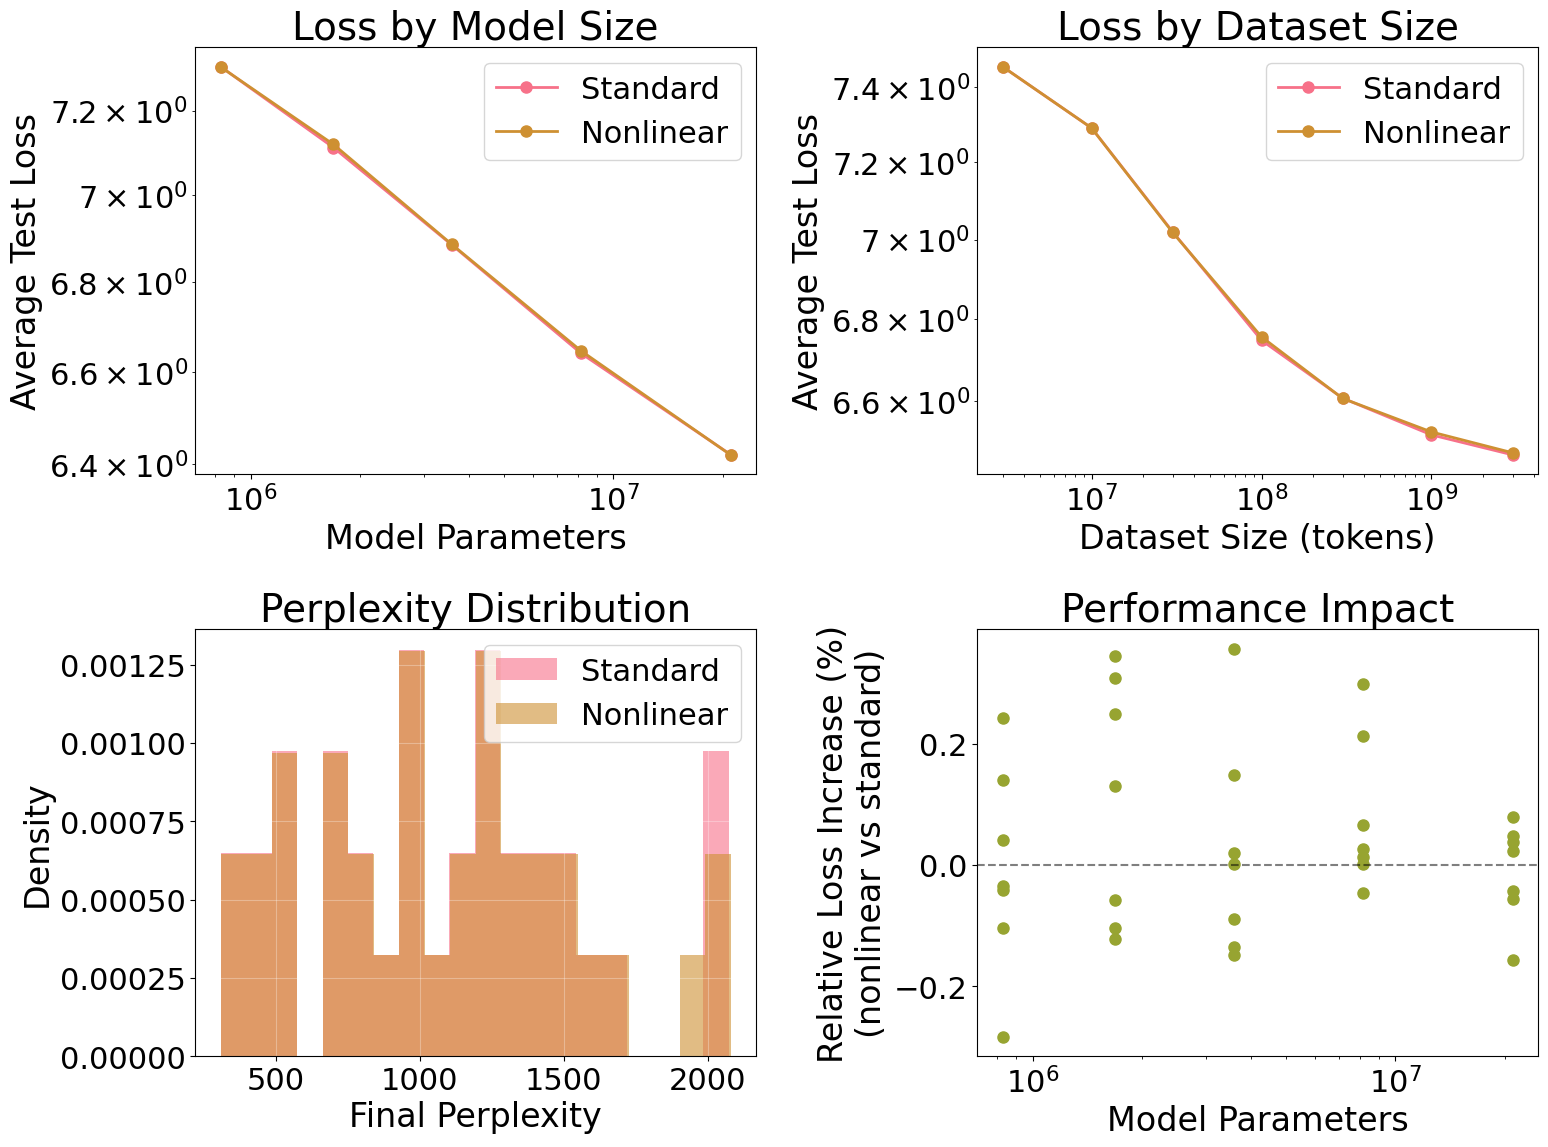


=== Comparing linear vs nonlinear ===


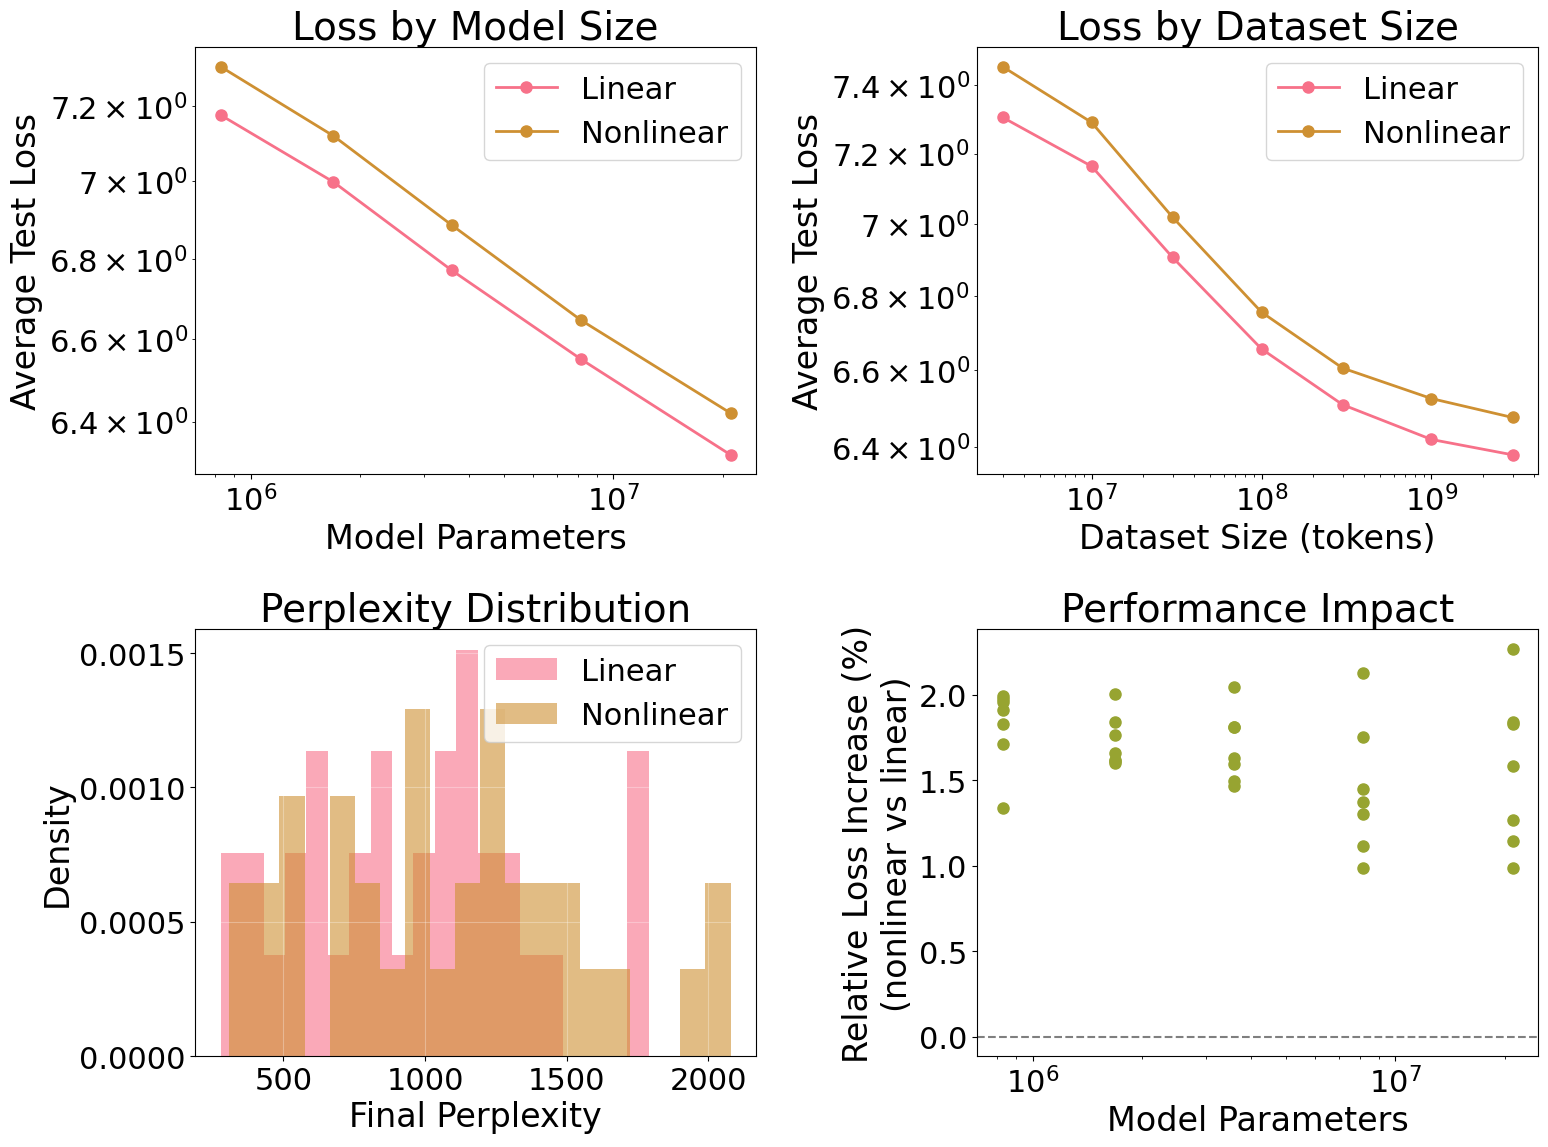

In [59]:
# Generate comparison plots for different experiment types
experiment_pairs = [
    ('standard', 'linear'),
    ('standard', 'nonlinear'),
    ('linear', 'nonlinear')
]

for type1, type2 in experiment_pairs:
    if type1 in experiment_types and type2 in experiment_types:
        print(f"\n=== Comparing {type1} vs {type2} ===")
        fig = compare_experiment_types(df, type1, type2)
        plt.show()
    else:
        print(f"\nSkipping comparison {type1} vs {type2} - not all types available")

### 6. Summary Statistics

In [60]:
# Print summary statistics
print("=== Summary Statistics ===")
print(f"Total experiments: {len(df)}")
print(f"Experiment types: {list(experiment_types)}")
print(f"Model parameter counts: {sorted(df['model_params'].unique())}")
print(f"Dataset sizes: {sorted(df['dataset_size'].unique())}")
print(f"Loss range: {df['final_loss'].min():.4f} - {df['final_loss'].max():.4f}")
print(f"Perplexity range: {df['final_perplexity'].min():.2f} - {df['final_perplexity'].max():.2f}")

if 'petaflop_days' in df.columns and df['petaflop_days'].notna().any():
    compute_data = df[df['petaflop_days'].notna()]
    print(f"Compute range: {compute_data['petaflop_days'].min():.6f} - {compute_data['petaflop_days'].max():.6f} PetaFLOP-days")

# Show experiment counts by type
print("\n=== Experiments by Type ===")
for exp_type in experiment_types:
    count = len(df[df['experiment_type'] == exp_type])
    print(f"{exp_type}: {count} experiments")

=== Summary Statistics ===
Total experiments: 117
Experiment types: ['standard', 'linear', 'nonlinear', 'clustering']
Model parameter counts: [827088, 1691872, 3582016, 8150400, 21026048]
Dataset sizes: [3000000, 10000000, 30000000, 100000000, 300000000, 1000000000, 3000000000]
Loss range: 5.6294 - 7.6392
Perplexity range: 278.50 - 2078.18
Compute range: 0.000001 - 0.013141 PetaFLOP-days

=== Experiments by Type ===
standard: 35 experiments
linear: 35 experiments
nonlinear: 35 experiments
clustering: 12 experiments


### 7. Power Law Fitting Analysis

In [61]:
# Analyze power law relationships for each experiment type
print("=== Power Law Analysis ===")

for exp_type in experiment_types:
    df_exp = df[df['experiment_type'] == exp_type]
    if len(df_exp) < 3:
        continue
        
    print(f"\n--- {exp_type.upper()} ---")
    
    # Model parameters vs loss
    if len(df_exp['model_params'].unique()) > 2:
        avg_loss_by_params = df_exp.groupby('model_params')['final_loss'].mean()
        log_params = np.log10(avg_loss_by_params.index.values)
        log_loss = np.log10(avg_loss_by_params.values)
        slope, intercept, r_value, _, _ = stats.linregress(log_params, log_loss)
        print(f"Loss ~ N^{slope:.3f} (α = {-slope:.3f}, R² = {r_value**2:.3f})")
    
    # Dataset size vs loss
    if len(df_exp['dataset_size'].unique()) > 2:
        log_data = np.log10(df_exp['dataset_size'].values)
        log_loss = np.log10(df_exp['final_loss'].values)
        slope, intercept, r_value, _, _ = stats.linregress(log_data, log_loss)
        print(f"Loss ~ D^{slope:.3f} (β = {-slope:.3f}, R² = {r_value**2:.3f})")
    
    # Compute vs loss (if available)
    df_compute = df_exp[df_exp['petaflop_days'].notna()]
    if len(df_compute) > 2:
        log_compute = np.log10(df_compute['petaflop_days'].values)
        log_loss = np.log10(df_compute['final_loss'].values)
        slope, intercept, r_value, _, _ = stats.linregress(log_compute, log_loss)
        print(f"Loss ~ C^{slope:.3f} (γ = {-slope:.3f}, R² = {r_value**2:.3f})")

=== Power Law Analysis ===

--- STANDARD ---
Loss ~ N^-0.041 (α = 0.041, R² = 0.999)
Loss ~ D^-0.022 (β = 0.022, R² = 0.483)
Loss ~ C^-0.027 (γ = 0.027, R² = 0.823)

--- LINEAR ---
Loss ~ N^-0.040 (α = 0.040, R² = 0.999)
Loss ~ D^-0.022 (β = 0.022, R² = 0.475)
Loss ~ C^-0.026 (γ = 0.026, R² = 0.816)

--- NONLINEAR ---
Loss ~ N^-0.041 (α = 0.041, R² = 0.999)
Loss ~ D^-0.022 (β = 0.022, R² = 0.479)
Loss ~ C^-0.027 (γ = 0.027, R² = 0.820)

--- CLUSTERING ---
Loss ~ D^-0.011 (β = 0.011, R² = 0.658)
Loss ~ C^-0.012 (γ = 0.012, R² = 0.744)
